[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L3/BA_L3_clustering/BA_L3_clustering.ipynb)

# BA_L3_clustering: Volatility clustering in Bitcoin returns

*Quantlet of Lecture 3, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Bitcoin daily log returns from 2018 to 18 September 2026 and the sample autocorrelations of returns, absolute returns and squared returns at lags 1-30 days, with the 5% band for an independent series: returns are hardly autocorrelated, absolute returns are autocorrelated at every lag (volatility clustering).

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Data.** Daily closes of Bitcoin (EOD Historical Data, EODHD), log returns in per cent $r_t = 100\ln(P_t/P_{t-1})$, 1 January 2018 – 18 September 2026.

**Method.** Sample autocorrelation $\hat\rho(k)$ of $r_t$, $|r_t|$ and $r_t^2$ for lags $k = 1, \dots, 30$ days. Under independence $\hat\rho(k)$ lies within $\pm 1.96/\sqrt n$ with probability 0.95 ($n$ = number of days).

**How to read.** Left: the return series, with calm and turbulent periods. Right: bars outside the dashed green band are significant at 5%.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]


R = {k: log_returns(ASSETS[k][0]) for k in ['Bitcoin']}
print({k: f'{len(r)} days, {r.index[0].date()} - {r.index[-1].date()}' for k, r in R.items()})

{'Bitcoin': '3183 days, 2018-01-01 - 2026-09-18'}


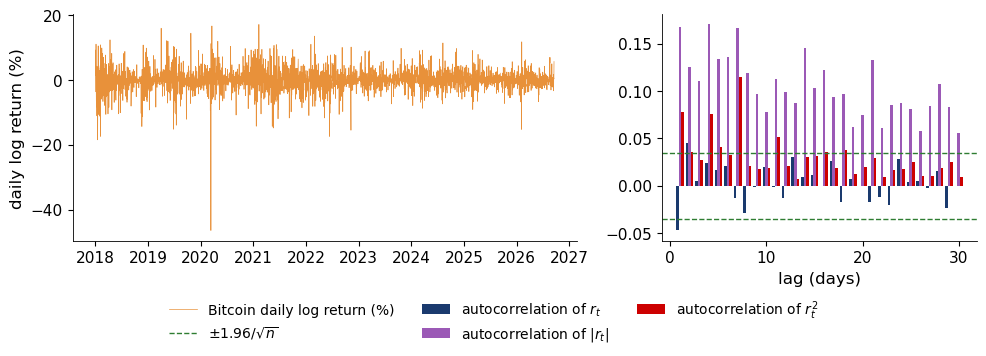

In [6]:
from statsmodels.tsa.stattools import acf
rb = R['Bitcoin']
lags = np.arange(1, 31)
a_r, a_abs, a_sq = acf(rb, nlags=30)[1:], acf(rb.abs(), nlags=30)[1:], acf(rb ** 2, nlags=30)[1:]
band = 1.96 / np.sqrt(len(rb))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].plot(rb.index, rb.values, lw=0.5, color=BTC, label='Bitcoin daily log return (%)')
ax[0].set_ylabel('daily log return (%)')
ax[1].bar(lags - 0.27, a_r, width=0.27, color=BLUE, label='autocorrelation of $r_t$')
ax[1].bar(lags, a_abs, width=0.27, color=ETH, label='autocorrelation of $|r_t|$')
ax[1].bar(lags + 0.27, a_sq, width=0.27, color=RED, label='autocorrelation of $r_t^2$')
ax[1].axhline(band, color=GREEN, ls='--', lw=1, label=r'$\pm 1.96/\sqrt{n}$')
ax[1].axhline(-band, color=GREEN, ls='--', lw=1)
ax[1].set_xlabel('lag (days)')
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.14, 1, 1))
save_fig(fig, 'ba_l3_clustering')

**Key numbers** (as on the slide).

In [7]:
pd.Series({'lags (of 30) outside the band: r_t': int((np.abs(a_r) > band).sum()),
           'lags (of 30) above the band: |r_t|': int((a_abs > band).sum()),
           'lags (of 30) above the band: r_t^2': int((a_sq > band).sum()),
           'smallest autocorrelation of |r_t|, lags 1-30': round(a_abs.min(), 2),
           'largest autocorrelation of |r_t|, lags 1-30': round(a_abs.max(), 2),
           'largest daily loss (%)': round(rb.min(), 1),
           'day of the largest loss': rb.idxmin().date()}).to_frame('value')

,value
lags (of 30) outside the band: r_t,2
lags (of 30) above the band: |r_t|,30
lags (of 30) above the band: r_t^2,8
"smallest autocorrelation of |r_t|, lags 1-30",0.06
"largest autocorrelation of |r_t|, lags 1-30",0.17
largest daily loss (%),-46.5
day of the largest loss,2020-03-12
